In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("employees.csv")
df.info()
print(df.dtypes)
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    object 
 1   Gender             855 non-null    object 
 2   Start Date         1000 non-null   object 
 3   Last Login Time    1000 non-null   object 
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    object 
dtypes: float64(1), int64(1), object(6)
memory usage: 62.6+ KB
First Name            object
Gender                object
Start Date            object
Last Login Time       object
Salary                 int64
Bonus %              float64
Senior Management     object
Team                  object
dtype: object
  First Name  Gender Start Date Last Login Time  Salary  Bonus %  \
0    Douglas    Male   8/6/1993       

In [3]:
print(df.isna().sum())

First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64


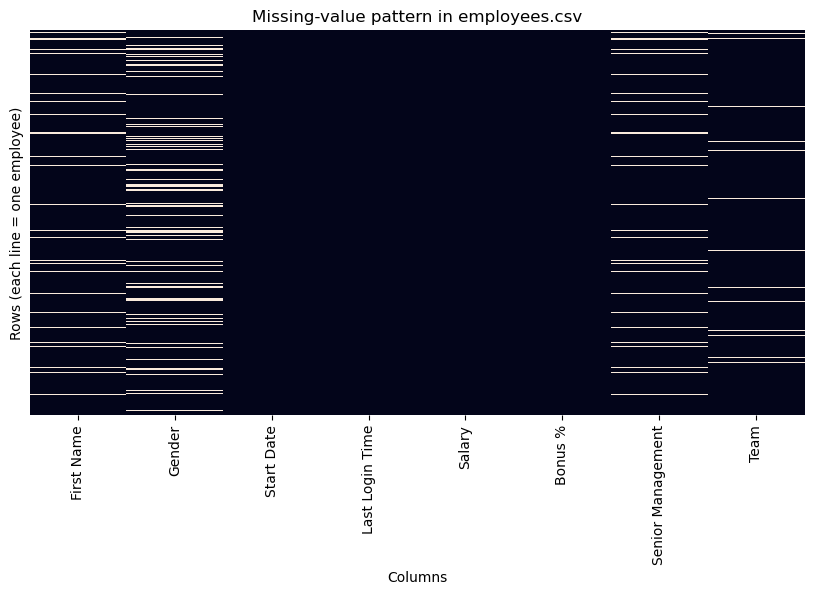

In [4]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missing-value pattern in employees.csv")
plt.xlabel("Columns")
plt.ylabel("Rows (each line = one employee)")
plt.show()

In [10]:
df2 = df.copy()
new_row = {
    "First Name": "-",
    "Gender": "na",
    "Start Date": np.nan,
    "Last Login Time": np.nan,
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": np.nan,
    "Team": np.nan,
}
df2 = pd.concat([df2, pd.DataFrame([new_row])], ignore_index=True)

In [14]:
print(df2.isna().sum())

First Name            68
Gender               146
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64


isna() only detects real missing markers: np.nan, None, pd.NaT.
'-' or 'na' is just a normal string so pandas cant know it means “no data”.

In [12]:
placeholders = {"-", "na", "n/a", ""}
obj_cols = df2.select_dtypes(include="object").columns

def to_nan(x):
    if isinstance(x, str) and x.strip().lower() in placeholders:
        return np.nan
    return x

df2[obj_cols] = df2[obj_cols].apply(lambda col: col.map(to_nan))
print(df2.isna().sum())

First Name            68
Gender               146
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64


In [16]:
cat_cols = ["Gender", "Senior Management", "Team"]   #most frequent
num_cols = ["Salary", "Bonus %"]   #median


#split first to prevent data leakage
train, test = train_test_split(df2, test_size=0.2, random_state=42)
train, test = train.copy(), test.copy()

cat_imp = SimpleImputer(strategy="most_frequent")
num_imp = SimpleImputer(strategy="median")

train[cat_cols] = cat_imp.fit_transform(train[cat_cols])
test[cat_cols]  = cat_imp.transform(test[cat_cols])

train[num_cols] = num_imp.fit_transform(train[num_cols])
test[num_cols]  = num_imp.transform(test[num_cols])

In [15]:
before = df2.isna().sum()
after = pd.concat([train, test]).isna().sum()
print(pd.DataFrame({"before": before, "after": after}))

                   before  after
First Name             68     68
Gender                146      0
Start Date              1      1
Last Login Time         1      1
Salary                  1      0
Bonus %                 1      0
Senior Management      68      0
Team                   44      0


### limitations of imputation
- invents values (median & mode fills shrink variance and distort distributions and correlations)
- it assumes data are missing at random (if missingness carries information imputing hides it)
- Mode fills bias 